## 1. Import libraries and configuration

In [19]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
DATA_PATH = Path("cleaned_grocery_data.csv")
FORECAST_HORIZON = 30

In [20]:
# Load data
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. "
        "Place cleaned_grocery_data.csv beside this notebook."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 23)


,Transaction_ID,Date,Customer_ID,Customer_Age_Group,City,Region,Store_ID,Category,Product_Name,Brand,...,Total_Amount_INR,Payment_Method,High_Discount_Flag,Gross_Revenue,Discount_Amount,Month,Quarter,Week,Revenue_Per_Unit,Is_Digital
0,TXN000001,2023-12-13,CUST9935,18-25,Chennai,South,STORE038,Dairy & Eggs,Milk,EcoFresh,...,2740.64,Cash,False,2740.64,0.00,12,4,50,342.580000,False
1,TXN000002,2023-10-15,CUST4257,55+,Bangalore,South,STORE027,Fruits & Vegetables,Banana,GreenLeaf,...,6103.84,UPI,False,6103.84,0.00,10,4,41,762.980000,True
2,TXN000003,2023-05-23,CUST3547,26-35,Hyderabad,South,STORE049,Grains & Pulses,Oats,TopBrand,...,5356.17,Cash,False,6301.38,945.21,5,2,21,892.695000,False
3,TXN000004,2023-01-23,CUST8527,55+,Mumbai,West,STORE008,Dairy & Eggs,Cream,EcoFresh,...,13745.92,Cash,False,15273.24,1527.32,1,1,4,1145.493333,False
4,TXN000005,2023-01-24,CUST4733,36-45,Lucknow,North,STORE006,Cleaning Supplies,Toilet Cleaner,GreenLeaf,...,10443.00,Cash,False,10443.00,0.00,1,1,4,870.250000,False


## 2. Data inspection

In [21]:
print("Columns:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nDuplicate rows:", df.duplicated().sum())

if "Date" not in df.columns or "Category" not in df.columns or "Quantity" not in df.columns:
    raise ValueError("Required columns missing. Expected Date, Category, and Quantity.")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Categories:", df["Category"].nunique())

Columns:
['Transaction_ID', 'Date', 'Customer_ID', 'Customer_Age_Group', 'City', 'Region', 'Store_ID', 'Category', 'Product_Name', 'Brand', 'Quantity', 'Unit_Price_INR', 'Discount_Percent', 'Total_Amount_INR', 'Payment_Method', 'High_Discount_Flag', 'Gross_Revenue', 'Discount_Amount', 'Month', 'Quarter', 'Week', 'Revenue_Per_Unit', 'Is_Digital']

Data types:


,dtype
Transaction_ID,object
Date,object
Customer_ID,object
Customer_Age_Group,object
City,object
Region,object
Store_ID,object
Category,object
Product_Name,object
Brand,object



Missing values:


,missing_count
Transaction_ID,0
Discount_Percent,0
Revenue_Per_Unit,0
Week,0
Quarter,0
Month,0
Discount_Amount,0
Gross_Revenue,0
High_Discount_Flag,0
Payment_Method,0



Duplicate rows: 0
Date range: 2023-01-01 00:00:00 to 2023-12-31 00:00:00
Categories: 10


## 3. Cleaning

In [22]:
data = df.copy()
data = data.drop_duplicates()
data = data.dropna(subset=["Date", "Category", "Quantity"])
data = data[data["Quantity"] >= 0].copy()

# Normalize category labels
data["Category"] = data["Category"].astype(str).str.strip()
data = data[data["Category"] != ""]

print("Shape after cleaning:", data.shape)
print("Remaining missing values in required fields:")
display(data[["Date", "Category", "Quantity"]].isna().sum())

Shape after cleaning: (10000, 23)
Remaining missing values in required fields:


Date        0
Category    0
Quantity    0
dtype: int64

## 4. Exploratory data analysis

Summary statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Transaction_ID,10000,10000,TXN000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,10000,NaN,NaN,NaN,2023-07-01 02:48:46.080000,2023-01-01 00:00:00,2023-03-31 00:00:00,2023-06-30 00:00:00,2023-09-30 00:00:00,2023-12-31 00:00:00,NaN
Customer_ID,10000,6055,CUST9078,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Age_Group,10000,5,46-55,2017,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,10000,10,Pune,1048,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,10000,4,North,3056,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_ID,10000,50,STORE041,222,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,10000,10,Frozen Foods,1079,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Name,10000,100,Ice Cream,119,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Brand,10000,10,PureLife,1029,NaN,NaN,NaN,NaN,NaN,NaN,NaN


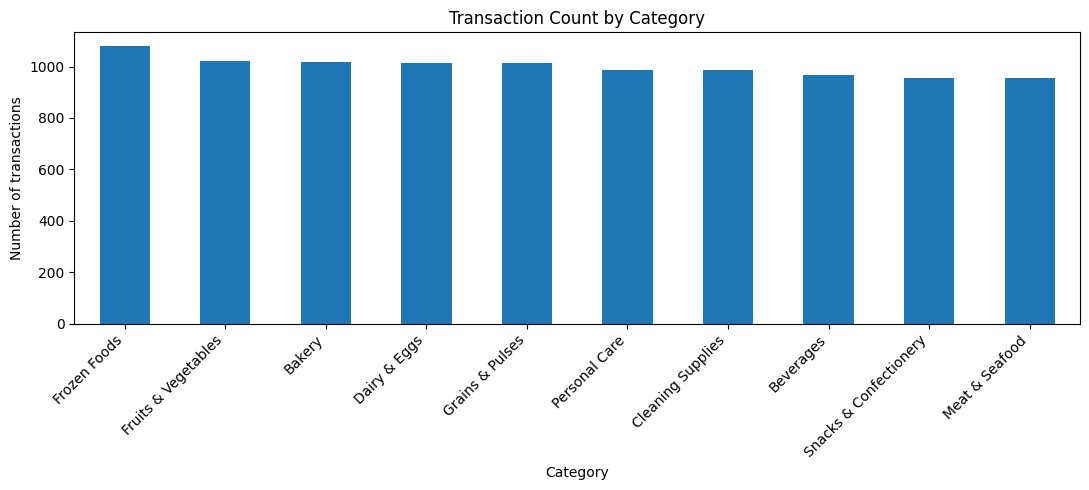

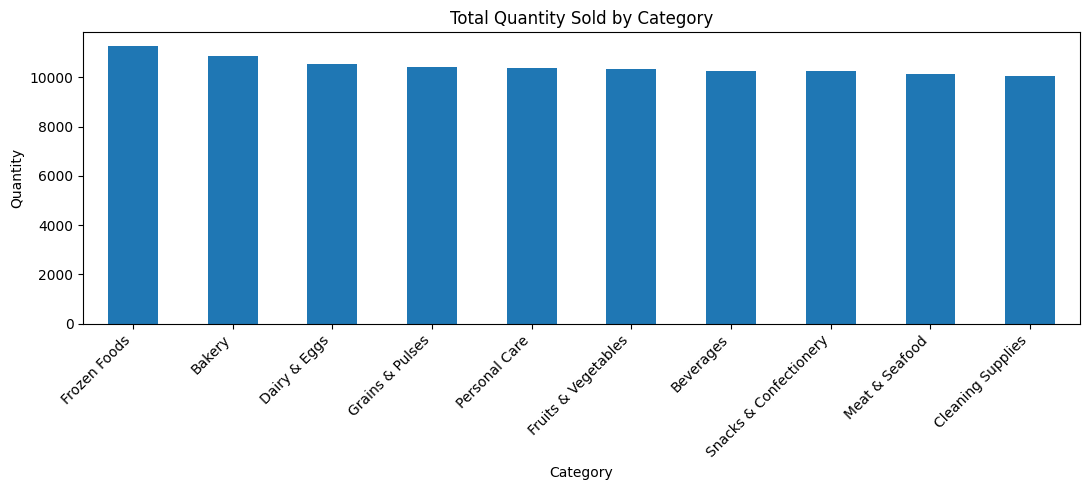

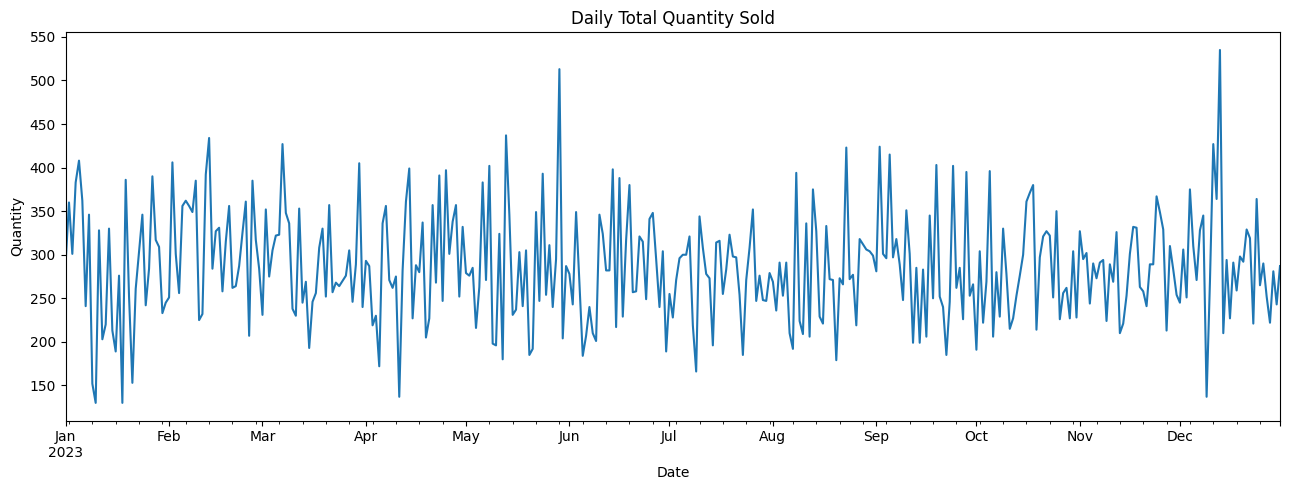

In [23]:
print("Summary statistics:")
display(data.describe(include="all").T)

# Transactions by category
category_transactions = data["Category"].value_counts().sort_values(ascending=False)
plt.figure(figsize=(11, 5))
category_transactions.plot(kind="bar")
plt.title("Transaction Count by Category")
plt.xlabel("Category")
plt.ylabel("Number of transactions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Quantity by category
category_quantity = data.groupby("Category")["Quantity"].sum().sort_values(ascending=False)
plt.figure(figsize=(11, 5))
category_quantity.plot(kind="bar")
plt.title("Total Quantity Sold by Category")
plt.xlabel("Category")
plt.ylabel("Quantity")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Daily total quantity
daily_total = data.groupby("Date")["Quantity"].sum().sort_index()
plt.figure(figsize=(13, 5))
daily_total.plot()
plt.title("Daily Total Quantity Sold")
plt.xlabel("Date")
plt.ylabel("Quantity")
plt.tight_layout()
plt.show()

## 5. Build daily category-level demand series

Transactions are aggregated to one observation per **date and category**. This provides a more stable first forecasting task than attempting to forecast every individual product with potentially sparse history.

In [24]:
daily = (
    data.groupby(["Date", "Category"], as_index=False)["Quantity"]
        .sum()
        .rename(columns={"Quantity": "Demand"})
)

all_dates = pd.date_range(daily["Date"].min(), daily["Date"].max(), freq="D")
categories = sorted(daily["Category"].unique())

full_index = pd.MultiIndex.from_product(
    [all_dates, categories], names=["Date", "Category"]
)
daily = (
    daily.set_index(["Date", "Category"])
         .reindex(full_index, fill_value=0)
         .reset_index()
         .sort_values(["Category", "Date"])
         .reset_index(drop=True)
)

display(daily.head())
print("Daily category rows:", len(daily))

,Date,Category,Demand
0,2023-01-01,Bakery,57
1,2023-01-02,Bakery,24
2,2023-01-03,Bakery,16
3,2023-01-04,Bakery,17
4,2023-01-05,Bakery,67


Daily category rows: 3650


## 6. Feature engineering

In [25]:
def add_features(frame):
    result = frame.copy()
    result["day"] = result["Date"].dt.day
    result["month"] = result["Date"].dt.month
    result["dayofweek"] = result["Date"].dt.dayofweek
    result["quarter"] = result["Date"].dt.quarter
    result["dayofyear"] = result["Date"].dt.dayofyear
    result["is_weekend"] = (result["dayofweek"] >= 5).astype(int)

    grouped = result.groupby("Category")["Demand"]
    for lag in [1, 7, 14]:
        result[f"lag_{lag}"] = grouped.shift(lag)

    # Shift before rolling to ensure today's target is not used as a feature.
    shifted = result.groupby("Category")["Demand"].shift(1)
    result["rolling_mean_7"] = (
        shifted.groupby(result["Category"]).rolling(7).mean()
        .reset_index(level=0, drop=True)
    )
    result["rolling_mean_30"] = (
        shifted.groupby(result["Category"]).rolling(30).mean()
        .reset_index(level=0, drop=True)
    )
    return result

featured = add_features(daily)
featured = featured.dropna().reset_index(drop=True)

feature_cols = [
    "day", "month", "dayofweek", "quarter", "dayofyear", "is_weekend",
    "lag_1", "lag_7", "lag_14", "rolling_mean_7", "rolling_mean_30"
]
display(featured.head())

,Date,Category,Demand,day,month,dayofweek,quarter,dayofyear,is_weekend,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_30
0,2023-01-31,Bakery,28,31,1,1,1,31,0,0.0,32.0,0.0,35.857143,28.966667
1,2023-02-01,Bakery,12,1,2,2,1,32,0,28.0,48.0,16.0,35.285714,28.000000
2,2023-02-02,Bakery,49,2,2,3,1,33,0,12.0,34.0,25.0,30.142857,27.600000
3,2023-02-03,Bakery,24,3,2,4,1,34,0,49.0,55.0,18.0,32.285714,28.700000
4,2023-02-04,Bakery,22,4,2,5,1,35,1,24.0,26.0,12.0,27.857143,28.933333


## 7. Chronological train-test split and baseline

In [26]:
# Split by date, not by randomly shuffled rows.
unique_dates = np.sort(featured["Date"].unique())
split_position = int(len(unique_dates) * 0.8)
split_date = pd.Timestamp(unique_dates[split_position])

train = featured[featured["Date"] < split_date].copy()
test = featured[featured["Date"] >= split_date].copy()

X_train, y_train = train[feature_cols], train["Demand"]
X_test, y_test = test[feature_cols], test["Demand"]

print("Training period:", train["Date"].min(), "to", train["Date"].max())
print("Testing period:", test["Date"].min(), "to", test["Date"].max())
print("Split date:", split_date)

# Seasonal-naive baseline: demand from the same category 7 days earlier.
baseline_pred = test["lag_7"].clip(lower=0)

Training period: 2023-01-31 00:00:00 to 2023-10-25 00:00:00
Testing period: 2023-10-26 00:00:00 to 2023-12-31 00:00:00
Split date: 2023-10-26 00:00:00


## 8. Train Random Forest

In [27]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_pred = np.clip(rf_model.predict(X_test), 0, None)

## 9. Train XGBoost

In [28]:
try:
    from xgboost import XGBRegressor

    xgb_model = XGBRegressor(
        n_estimators=400,
        max_depth=5,
        learning_rate=0.04,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    xgb_model.fit(X_train, y_train)
    xgb_pred = np.clip(xgb_model.predict(X_test), 0, None)
    xgb_available = True
except ImportError:
    print("XGBoost is not installed. Run `%pip install xgboost` and rerun this section.")
    xgb_available = False

## 10. Evaluate models

In [29]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    nonzero = actual != 0
    mape = (
        np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])) * 100
        if nonzero.any() else np.nan
    )
    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape}

predictions = {
    "Lag-7 baseline": baseline_pred,
    "Random Forest": rf_pred
}
if xgb_available:
    predictions["XGBoost"] = xgb_pred

metrics = pd.DataFrame({
    name: calculate_metrics(y_test, pred)
    for name, pred in predictions.items()
}).T.sort_values("RMSE")

display(metrics)

# MAPE excludes zero-actual observations; it can still be unstable for very small actual values.

,MAE,RMSE,MAPE (%)
Random Forest,15.660884,19.490318,130.554198
XGBoost,16.262135,20.107935,130.090667
Lag-7 baseline,21.298507,27.163903,150.756711


## 11. Actual vs predicted demand

,Date,Category,Demand,Predicted_Demand
268,2023-10-26,Bakery,43,34.128192
269,2023-10-27,Bakery,67,32.442959
270,2023-10-28,Bakery,13,33.711415
271,2023-10-29,Bakery,21,34.606078
272,2023-10-30,Bakery,16,27.588804
273,2023-10-31,Bakery,26,33.396030
274,2023-11-01,Bakery,7,29.003443
275,2023-11-02,Bakery,18,34.145563
276,2023-11-03,Bakery,16,31.452607
277,2023-11-04,Bakery,18,29.161060


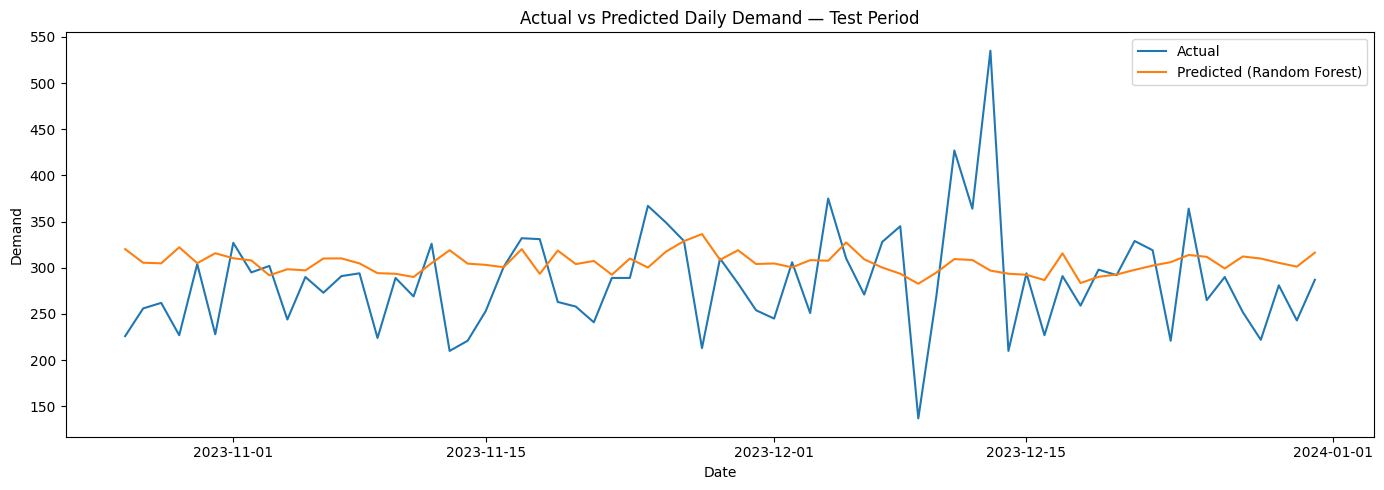

In [30]:
best_model_name = metrics.index[0]
best_predictions = predictions[best_model_name]

comparison = test[["Date", "Category", "Demand"]].copy()
comparison["Predicted_Demand"] = best_predictions
display(comparison.head(15))

# Plot overall daily actual and predicted demand in the test period.
plot_data = comparison.groupby("Date")[["Demand", "Predicted_Demand"]].sum()
plt.figure(figsize=(14, 5))
plt.plot(plot_data.index, plot_data["Demand"], label="Actual")
plt.plot(plot_data.index, plot_data["Predicted_Demand"], label=f"Predicted ({best_model_name})")
plt.title("Actual vs Predicted Daily Demand — Test Period")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.tight_layout()
plt.show()

## 12. Feature importance

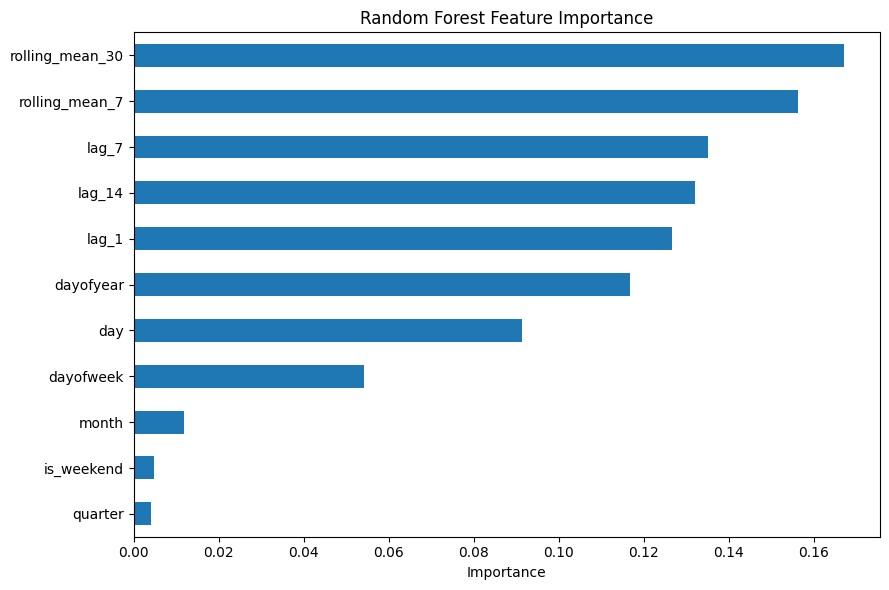

In [31]:
if best_model_name == "Random Forest":
    importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values()
    plt.figure(figsize=(9, 6))
    importances.plot(kind="barh")
    plt.title("Random Forest Feature Importance")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
elif xgb_available and best_model_name == "XGBoost":
    importances = pd.Series(xgb_model.feature_importances_, index=feature_cols).sort_values()
    plt.figure(figsize=(9, 6))
    importances.plot(kind="barh")
    plt.title("XGBoost Feature Importance")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print("The baseline model does not provide feature importance.")

## 13. Train the selected model on all available history

In [32]:
if best_model_name == "Random Forest":
    final_model = RandomForestRegressor(
        n_estimators=300, max_depth=12, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    )
elif best_model_name == "XGBoost" and xgb_available:
    final_model = XGBRegressor(
        n_estimators=400, max_depth=5, learning_rate=0.04,
        subsample=0.9, colsample_bytree=0.9,
        objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1
    )
else:
    final_model = None

if final_model is not None:
    final_model.fit(featured[feature_cols], featured["Demand"])
    print("Selected model refitted:", best_model_name)
else:
    print("The lag-7 baseline is best; future forecasts will use the seasonal-naive method.")

Selected model refitted: Random Forest


## 14. Generate future demand forecasts

In [33]:
def make_future_forecast(history, model, horizon=30):
    outputs = []
    history = history[["Date", "Category", "Demand"]].copy()
    last_date = history["Date"].max()

    for category in sorted(history["Category"].unique()):
        series = (
            history[history["Category"] == category]
            .sort_values("Date")["Demand"]
            .astype(float).tolist()
        )

        for step in range(1, horizon + 1):
            forecast_date = last_date + pd.Timedelta(days=step)
            row = {
                "Date": forecast_date,
                "Category": category,
                "day": forecast_date.day,
                "month": forecast_date.month,
                "dayofweek": forecast_date.dayofweek,
                "quarter": forecast_date.quarter,
                "dayofyear": forecast_date.dayofyear,
                "is_weekend": int(forecast_date.dayofweek >= 5),
                "lag_1": series[-1],
                "lag_7": series[-7],
                "lag_14": series[-14],
                "rolling_mean_7": float(np.mean(series[-7:])),
                "rolling_mean_30": float(np.mean(series[-30:]))
            }

            if model is None:
                prediction = row["lag_7"]
            else:
                prediction = model.predict(pd.DataFrame([row])[feature_cols])[0]

            prediction = max(0.0, float(prediction))
            outputs.append({
                "Date": forecast_date,
                "Category": category,
                "Forecast_Demand": prediction
            })
            series.append(prediction)

    return pd.DataFrame(outputs)

future_forecast = make_future_forecast(daily, final_model, FORECAST_HORIZON)
display(future_forecast.head(20))

,Date,Category,Forecast_Demand
0,2024-01-01,Bakery,34.924569
1,2024-01-02,Bakery,30.473313
2,2024-01-03,Bakery,24.167177
3,2024-01-04,Bakery,23.708546
4,2024-01-05,Bakery,25.816570
5,2024-01-06,Bakery,27.937394
6,2024-01-07,Bakery,39.546849
7,2024-01-08,Bakery,33.673741
8,2024-01-09,Bakery,29.452418
9,2024-01-10,Bakery,26.343751


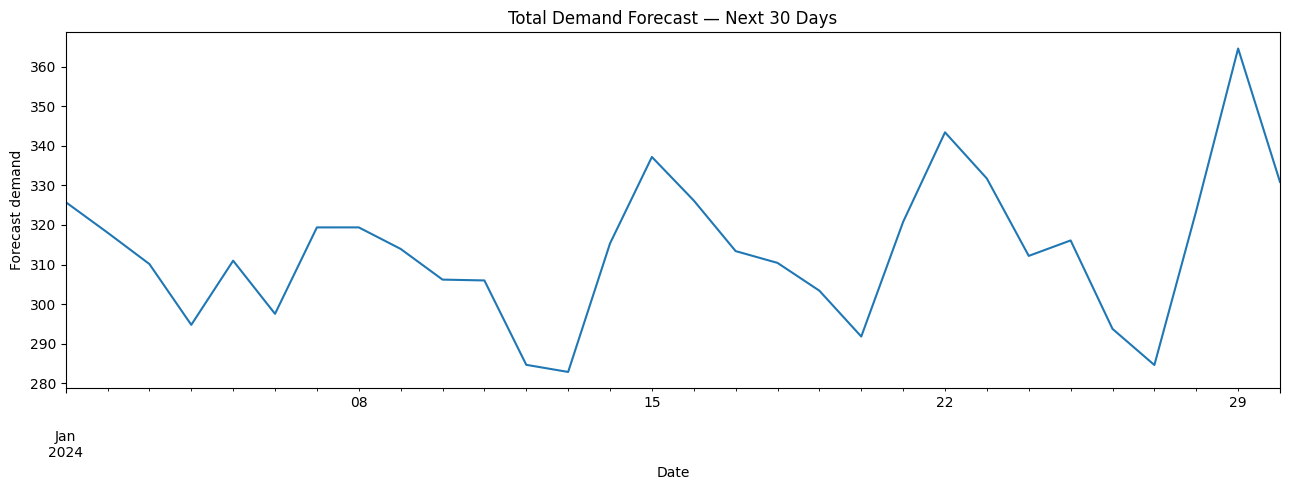

,Forecast_Quantity_Next_30_Days
Category,
Meat & Seafood,999.577883
Snacks & Confectionery,963.216084
Grains & Pulses,963.112007
Personal Care,954.042342
Beverages,944.923913
Frozen Foods,944.910656
Dairy & Eggs,935.990321
Cleaning Supplies,933.302735
Fruits & Vegetables,895.872745


In [34]:
future_total = future_forecast.groupby("Date")["Forecast_Demand"].sum()
plt.figure(figsize=(13, 5))
future_total.plot()
plt.title(f"Total Demand Forecast — Next {FORECAST_HORIZON} Days")
plt.xlabel("Date")
plt.ylabel("Forecast demand")
plt.tight_layout()
plt.show()

category_forecast = (
    future_forecast.groupby("Category")["Forecast_Demand"]
    .sum().sort_values(ascending=False)
)
display(category_forecast.to_frame("Forecast_Quantity_Next_30_Days"))

## 15. Prediction system — enter a category and forecast horizon

    Use this section to request a demand prediction for a selected category. It uses the trained model (or the lag-7 baseline if that was the best model) and recursively forecasts one day at a time.

    Change `selected_category` and `days_to_predict` below, then run the cell.

In [35]:
def predict_demand(category, days=7):
    category = str(category).strip()
    if category not in set(daily["Category"].astype(str)):
        raise ValueError(
            f"Unknown category: {category}. Available categories: "
            + ", ".join(sorted(daily["Category"].astype(str).unique()))
        )
    if not isinstance(days, int) or days < 1 or days > 90:
        raise ValueError("days must be an integer from 1 to 90.")

    category_history = (
        daily[daily["Category"].astype(str) == category]
        .sort_values("Date")["Demand"]
        .astype(float)
        .tolist()
    )
    last_date = daily["Date"].max()
    results = []

    for step in range(1, days + 1):
        forecast_date = last_date + pd.Timedelta(days=step)
        row = {
            "day": forecast_date.day,
            "month": forecast_date.month,
            "dayofweek": forecast_date.dayofweek,
            "quarter": forecast_date.quarter,
            "dayofyear": forecast_date.dayofyear,
            "is_weekend": int(forecast_date.dayofweek >= 5),
            "lag_1": category_history[-1],
            "lag_7": category_history[-7],
            "lag_14": category_history[-14],
            "rolling_mean_7": float(np.mean(category_history[-7:])),
            "rolling_mean_30": float(np.mean(category_history[-30:])),
        }

        if final_model is None:
            predicted = row["lag_7"]
        else:
            predicted = float(
                final_model.predict(pd.DataFrame([row])[feature_cols])[0]
            )

        predicted = max(0.0, predicted)
        results.append({
            "Date": forecast_date,
            "Category": category,
            "Predicted_Demand": predicted,
        })
        category_history.append(predicted)

    return pd.DataFrame(results)

# USER INPUTS ? edit these two values
selected_category = sorted(
    daily["Category"].astype(str).str.strip().unique()
)[0]
days_to_predict = 7

user_prediction = predict_demand(selected_category, days_to_predict)
display(user_prediction)

print(
    f"Total predicted demand for {selected_category} "
    f"over the next {days_to_predict} days: "
    f"{user_prediction['Predicted_Demand'].sum():.2f}"
)


,Date,Category,Predicted_Demand
0,2024-01-01,Bakery,34.924569
1,2024-01-02,Bakery,30.473313
2,2024-01-03,Bakery,24.167177
3,2024-01-04,Bakery,23.708546
4,2024-01-05,Bakery,25.816570
5,2024-01-06,Bakery,27.937394
6,2024-01-07,Bakery,39.546849


Total predicted demand for Bakery over the next 7 days: 206.57


**How to use:** Set `selected_category` to any category present in the dataset and set `days_to_predict` to a number from 1 to 90. Run the cell to get daily predictions and the total predicted demand. These are model estimates, not guaranteed sales.

## 16. Save results

In [36]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

daily.to_csv(output_dir / "daily_category_demand.csv", index=False)
metrics.to_csv(output_dir / "model_comparison.csv")
comparison.to_csv(output_dir / "test_predictions.csv", index=False)
future_forecast.to_csv(output_dir / "future_demand_forecast.csv", index=False)

print("Saved outputs to:", output_dir.resolve())

Saved outputs to: D:\Downloads\data science project\Retail_Demand_Prediction_Simple_Dashboard\outputs
